In [2]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)
import numpy as np

def evaluate_model(y_true, y_pred, scores, inference_time, threshold=0.2, model_name="Model"):
    """
    Evaluates a model and returns metrics formatted for copy-pasting.
    
    Parameters:
        y_true (np.array): Ground truth labels (0=normal, 1=anomaly).
        scores (np.array): Anomaly scores (lower = more anomalous).
        threshold (float): Threshold for anomaly decision.
        model_name (str): Name of the model.
        
    Returns:
        dict: Dictionary of metrics (can print or format for LaTeX).
    """

    precision = precision_score(y_true, y_pred, zero_division=0)
    accuracy = accuracy_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auroc = roc_auc_score(y_true, scores)

    cm = confusion_matrix(y_true, y_pred)
    clf_report = classification_report(y_true, y_pred, digits=2)

    result = {
        "Model": model_name,
        "Precision": f"{precision:.3f}",
        "Accuracy": f"{accuracy:.3f}",
        "Recall": f"{recall:.3f}",
        "F1-Score": f"{f1:.3f}",
        "Matrix": f"TP={cm[1,1]}, FP={cm[0,1]}, FN={cm[1,0]}, TN={cm[0,0]}",
        "AUROC": f"{auroc:.3f}",
        "Inference Time (s)": f"{inference_time:.4f}",
        "Clf Report": clf_report.strip()
    }

    return result


In [41]:
import tensorflow as tf
from keras import layers
import pandas as pd

# @tf.keras.utils.register_keras_serializable()
# class AnomalyDetector(tf.keras.Model):
#     def __init__(self, **kwargs):
#         super(AnomalyDetector, self).__init__(**kwargs)
#         self.encoder = tf.keras.Sequential([
#           # layers.Dense(16, activation="relu"),
#           # # Model was overfitting so add dropout layers
#           # layers.Dropout(0.2),
#           # layers.Dense(8, activation="relu"),
#           # layers.Dropout(0.2),
#           # layers.Dense(4, activation="relu")

#             layers.Dense(32, activation=None),
#             layers.BatchNormalization(),
#             layers.LeakyReLU(),
#             layers.Dropout(0.1),
#             layers.Dense(16, activation=None),
#             layers.BatchNormalization(),
#             layers.LeakyReLU(),
#             layers.Dense(8, activation=None),
#             layers.BatchNormalization(),
#             layers.LeakyReLU()
#         ])
    
#         self.decoder = tf.keras.Sequential([

#             layers.Dense(16, activation=None),
#             layers.BatchNormalization(),
#             layers.LeakyReLU(),
#             layers.Dropout(0.1),
#             layers.Dense(32, activation=None),
#             layers.BatchNormalization(),
#             layers.LeakyReLU(),
#             layers.Dense(24)
            
#           # layers.Dense(8, activation="relu"),
#           # layers.Dropout(0.2),
#           # layers.Dense(16, activation="relu"),
#           # layers.Dropout(0.1),
#           # layers.Dense(24)
#         ])
      
#     def call(self, x):
#         encoded = self.encoder(x)
#         decoded = self.decoder(encoded)
#         return decoded

#     def get_config(self):
#         # Return config dictionary; empty because no constructor args
#         base_config = super(AnomalyDetector, self).get_config()
#         return base_config

#     @classmethod
#     def from_config(cls, config):
#         return cls(**config)

@tf.keras.utils.register_keras_serializable()
class AnomalyDetector(tf.keras.Model):
    def __init__(self, latent_dim=8, **kwargs):
        super().__init__(**kwargs)

        # Encoder
        self.encoder = tf.keras.Sequential([
            layers.Dense(32, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dropout(0.1),
            layers.Dense(16, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dense(latent_dim, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
        ])

        # Decoder
        self.decoder = tf.keras.Sequential([
            layers.Dense(16, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dropout(0.1),
            layers.Dense(32, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dense(24)  # output dim
        ])

        # NCE Classifier Head
        self.classifier = tf.keras.Sequential([
            layers.Dense(8, activation='relu'),
            layers.Dense(1, activation='sigmoid')  # p(normal)
        ])

    def call(self, x):
        z = self.encoder(x)
        reconstruction = self.decoder(z)
        classification = self.classifier(z)
        return reconstruction, classification

    def get_config(self):
        base_config = super().get_config()
        return base_config

    @classmethod
    def from_config(cls, config):
        return cls(**config)

In [42]:
cae_model = tf.keras.models.load_model(
    "Models/CAE/8f_cae_nce_model.keras",
    custom_objects={"AnomalyDetector": AnomalyDetector}
)

In [11]:
transformed_training_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_training_data.csv')

# 1. Extract labels (column 6)
training_labels = transformed_training_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
training_data = transformed_training_data.drop(
    columns=[transformed_training_data.columns[6], transformed_training_data.columns[7]]
)

# 3. Convert to float32 tensor
training_data = tf.convert_to_tensor(training_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
training_labels = tf.convert_to_tensor(training_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_training_data = tf.boolean_mask(training_data, ~training_labels)
anomalous_training_data = tf.boolean_mask(training_data, training_labels)

In [12]:
transformed_testing_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_testing_data.csv')

# 1. Extract labels (column 6)
testing_labels = transformed_testing_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
testing_data = transformed_testing_data.drop(
    columns=[transformed_testing_data.columns[6], transformed_testing_data.columns[7]]
)

# 3. Convert to float32 tensor
testing_data = tf.convert_to_tensor(testing_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
testing_labels = tf.convert_to_tensor(testing_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_testing_data = tf.boolean_mask(testing_data, ~testing_labels)
anomalous_testing_data = tf.boolean_mask(testing_data, testing_labels)

In [13]:
transformed_validation_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_validation_data.csv')

# 1. Extract labels (column 6)
validation_labels = transformed_validation_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
validation_data = transformed_validation_data.drop(
    columns=[transformed_validation_data.columns[6], transformed_validation_data.columns[7]]
)

# 3. Convert to float32 tensor
validation_data = tf.convert_to_tensor(validation_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
validation_labels = tf.convert_to_tensor(validation_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_validation_data = tf.boolean_mask(validation_data, ~validation_labels)
anomalous_validation_data = tf.boolean_mask(validation_data, validation_labels)

In [21]:
import time

def predict(model, data, threshold):
    start_time = time.time()
    reconstructions = model(data)
    loss = tf.keras.losses.mae(reconstructions, data)
    # Detects if value greater than threshold then return true (for suspicious) else false (not suspicious)
    preds = tf.math.greater(loss, threshold)
    end_time = time.time()
    inference_time = end_time - start_time
    return loss.numpy(), preds.numpy().astype(int), inference_time

def predict_nce(model, data, threshold=None, alpha=0.5):
    """
    Predict anomaly scores for a model with reconstruction + NCE classifier.

    Parameters:
        model : tf.keras.Model
            The trained NCE autoencoder model.
        data : np.ndarray or tf.Tensor
            Input data to score.
        threshold : float, optional
            If given, used to convert anomaly scores to binary predictions.
            If None, returns raw anomaly scores.
        alpha : float
            Weight between reconstruction error and classifier anomaly score.

    Returns:
        anomaly_scores : np.ndarray
            Combined anomaly score per sample.
        predictions : np.ndarray
            Binary predictions (0=normal, 1=anomaly). Only returned if threshold is set.
        inference_time : float
            Total time taken to run prediction.
    """
    start_time = time.time()

    # Forward pass
    reconstructions, classifier_probs = model(data, training=False)

    # Reconstruction error per sample
    recon_error = np.mean(np.abs(reconstructions - data), axis=1)

    # Classifier score -> anomaly score (high = more anomalous)
    classifier_score = 1 - classifier_probs.numpy().flatten()

    # Combined anomaly score
    anomaly_scores = alpha * recon_error + (1 - alpha) * classifier_score

    predictions = None
    if threshold is not None:
        predictions = (anomaly_scores > threshold).astype(int)

    end_time = time.time()
    inference_time = end_time - start_time

    if predictions is not None:
        return anomaly_scores, predictions, inference_time
    else:
        return anomaly_scores, inference_time

In [23]:
# reconstructions, classifications = cae_model.predict(training_data)
# # reconstructions = cae_model.predict(training_data)
# reconstructions_error = tf.keras.losses.mae(reconstructions, training_data)

# # Calculate mean and std of the reconstruction errors
# mean_error = np.mean(reconstructions_error)
# std_error = np.std(reconstructions_error)

# # Set threshold to be mean + N * std, where N is a hyperparameter you can tune
# threshold = mean_error + 2 * std_error  # For a more aggressive threshold, decrease the multiplier

anomaly_scores, _ = predict_nce(cae_model, training_data)
threshold = np.mean(anomaly_scores) + 2 * np.std(anomaly_scores)

print("Threshold: ", threshold)

# Make predictions based on the threshold
predictions = reconstructions_error > threshold

Threshold:  0.13479103


In [39]:
# Get predictions
# threshold = 0.13479103

# scores, y_pred, inference_time = predict(cae_model, testing_data, threshold=threshold)
scores, y_pred, inf_time = predict_nce(cae_model, testing_data, threshold=threshold)

# Your true labels for this test data
y_true = testing_labels  # shape should be (n_samples,), values = 0 or 1

metrics = evaluate_model(
    y_true=y_true,
    y_pred=y_pred,
    scores=scores,
    inference_time=inference_time,
    threshold=threshold,
    model_name="8F Classical AE"
)

# Print clean table row for your notes
for k, v in metrics.items():
    print(f"{k}: {v}")


Model: 8F Classical AE
Precision: 0.929
Accuracy: 0.900
Recall: 0.964
F1-Score: 0.946
Matrix: TP=165320, FP=12673, FN=6139, TN=4835
AUROC: 0.943
Inference Time (s): 0.1547
Clf Report: precision    recall  f1-score   support

       False       0.44      0.28      0.34     17508
        True       0.93      0.96      0.95    171459

    accuracy                           0.90    188967
   macro avg       0.68      0.62      0.64    188967
weighted avg       0.88      0.90      0.89    188967


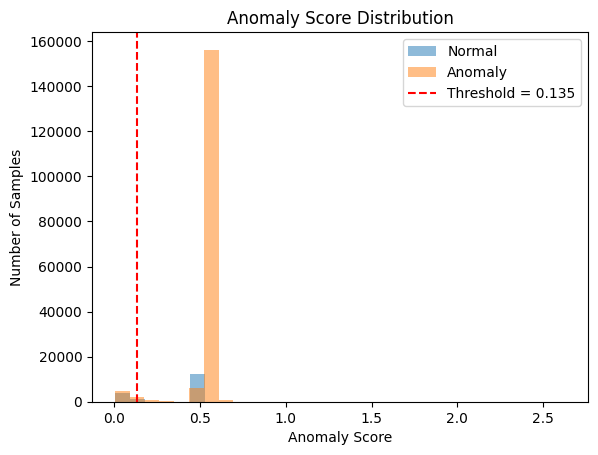

In [40]:
import matplotlib.pyplot as plt
# --- Histogram of scores ---
plt.hist(scores[y_true.numpy() == 0], bins=30, alpha=0.5, label='Normal')
plt.hist(scores[y_true.numpy() == 1], bins=30, alpha=0.5, label='Anomaly')
plt.axvline(threshold, color='red', linestyle='--', label=f"Threshold = {threshold:.3f}")
plt.xlabel("Anomaly Score")
plt.ylabel("Number of Samples")
plt.title("Anomaly Score Distribution")
plt.legend()
plt.show()